# 01 · Preprocessing — Dong 2020 Neuroblastoma (malignant compartment)

Isolate malignant cells across the two capture groups, threshold thin samples, integrate
`sample` with Harmony, embed, split compartments, and judge **Gate 1** (batch mixing &
manifold continuity) on the regenerated embedding. Neuroblastoma (Neuroendocrine), 10x,
13 tumours. Every dataset-dependent choice is *derived here*, not inherited from the Puram
protocol.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd, anndata as ad
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.sparse.csgraph import connected_components
from sklearn.neighbors import NearestNeighbors
import scipy.sparse as sp
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

### Paths — notebook runs in place
The `Neuroendocrine/` category partition puts this notebook **six** levels below the
`EMToolbox` root (`.../CCCA/Claude/Neuroendocrine/Dong2020_Neuroendocrine/`), one deeper
than the Puram reference — so the relative-path stem is `os.pardir*6`.

In [2]:
name = os.path.basename(os.getcwd())                    # Dong2020_Neuroendocrine
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Neuroendocrine
pth  = os.path.join(*([os.pardir]*4))                   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
pth_in   = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)
pth_out  = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig  = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb   = os.path.join(pth_fig, 'colorbars')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Dong2020_Neuroendocrine | category: Neuroendocrine


### Load malignant compartment — nested leaves, shared gene panel
Dong 2020 is **nested by capture group**: `Group1` (10 tumours, 12 595 genes) and `Group2`
(3 tumours, 33 490 genes) each have their own matrix/gene/cell files. Following `merge.py`, I
walk to the leaf directories (those with no sub-directories) and load each with the shared
`load_CCCA_adata` loader, then concatenate.

The two panels differ (intersection 12 113; Group2 carries 21 377 genes absent from Group1). An
**outer** join would encode those 21 377 genes as structurally-missing for all Group1 cells — a
batch signal perfectly confounded with `sample`/group that Harmony cannot remove and that would
manufacture the very per-sample split Gate 1 tests for. I therefore concatenate on the **shared
panel** (`join='inner'`), so all 13 tumours live in one comparable feature space. The embryonic
modules still recover well on the shared panel (Gast 52, pSom 62, Crest 80 genes).

In [3]:
from scripts.load import load_CCCA_adata
leaves = sorted(dp for dp, sd, _ in os.walk(pth_in) if len(sd) == 0)
print('leaf matrix dirs:', [os.path.basename(l) for l in leaves])
ads = {os.path.basename(l): load_CCCA_adata(l, verbose=False) for l in leaves}
for k, a in ads.items():
    print(f'  {k}: {a.shape}  genes={a.n_vars}  malignant={(a.obs.celltype=="Malignant").sum()}')
inter = set.intersection(*[set(a.var_names) for a in ads.values()])
print('shared-panel size (inner join):', len(inter))
adata = ad.concat(ads, join='inner', merge='same', label='source')
adata.obs_names_make_unique()
print('concatenated (shared panel):', adata.shape)
adata = adata[adata.obs.celltype == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique(),
      '| per-group:', adata.obs['source'].value_counts().to_dict())

leaf matrix dirs: ['Group1', 'Group2']
  Group1: (26433, 12595)  genes=12595  malignant=22514
  Group2: (28757, 33490)  genes=33490  malignant=24870
shared-panel size (inner join): 12113
concatenated (shared panel): (55190, 12113)
malignant: (47384, 12113) | samples: 13 | per-group: {'Group2': 24870, 'Group1': 22514}


### Sample thresholding — multiplicative gap-finding, with a floor fallback
Sort per-sample malignant counts and look for a **dominant multiplicative gap** to cut at (C3:
the rule needs a *clean* gap to be well-defined). Here the largest gap (845→428, ratio 1.97) is
only **1.06×** the runner-up gap — no dominant cliff, and it would split two well-populated
tumours. The premise fails, so I fall back to the **≥100-cell floor** (Steele/Qian/Peng
degenerate-gap precedent). Every one of the 13 tumours clears it (min 364 cells), so all 13 are
kept — discarding six real tumours on a non-cliff gap would gut Gate 1.

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios))
dominance = ratios[gap] / np.sort(ratios)[-2]
print('sorted per-sample malignant counts:'); print(n.to_string())
print(f'\nlargest multiplicative gap: {int(vals[gap])} -> {int(vals[gap+1])} '
      f'(ratio {ratios[gap]:.2f}); dominance vs runner-up = {dominance:.2f}x (>=1.5 = clean cliff)')
if dominance >= 1.5:
    thresh = int(np.sqrt(vals[gap]*vals[gap+1])); rule = f'geometric-mean cut across dominant gap = {thresh}'
else:
    thresh = 100; rule = 'gap non-dominant (C3 premise fails) -> fall back to >=100 floor'
print('threshold rule:', rule)
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples (min per-sample={int(n.min())}) -> {adata.shape[0]} cells')

sorted per-sample malignant counts:
sample
Tumor_230    10945
Tumor_200     9126
Tumor_69      5432
Tumor_71      5316
Tumor_162     4799
Tumor_44      2572
Tumor_75      2497
Tumor_34      2362
Tumor_92      1750
Tumor_40       948
Tumor_10       845
Tumor_27       428
Tumor_19       364

largest multiplicative gap: 845 -> 428 (ratio 1.97); dominance vs runner-up = 1.06x (>=1.5 = clean cliff)
threshold rule: gap non-dominant (C3 premise fails) -> fall back to >=100 floor
kept 13/13 samples (min per-sample=364) -> 47384 cells


### Overdispersion, PCA, Harmony integration, embedding
Over-dispersed gene selection (scFates GAM), PCA, then Harmony on `sample`. `n_pcs` and `theta`
are *derived*: the scree elbow sits very low (PC≈5) but the atlas precedents run 20–40, so I take
**n_pcs=20** as the robust floor (attempt-1 Chen lesson: an over-cut elbow forces a
patient-segregated read). `theta` is chosen by a same-sample-neighbour sweep below — the two
capture groups are a strong batch (source iLISI 1.00 at θ=0), so integration strength matters.

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('over-dispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
vr = adata.uns['pca']['variance_ratio']
x = np.arange(1,51); x1,y1,x2,y2 = x[0],vr[0],x[-1],vr[-1]
d = np.abs((y2-y1)*x-(x2-x1)*vr+x2*y1-y2*x1)/np.hypot(y2-y1,x2-x1)
print(f'scree elbow at PC {int(x[np.argmax(d)])} (biases low on dense 10x); '
      f'n_pcs=20 chosen as robust floor (atlas precedent 20-40)')
print('cum var @10/20/30 PC:', [round(np.cumsum(vr)[k-1],3) for k in (10,20,30)])

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 1579 over-dispersed features (0:00:07) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

over-dispersed genes: 1579
scree elbow at PC 5 (biases low on dense 10x); n_pcs=20 chosen as robust floor (atlas precedent 20-40)
cum var @10/20/30 PC: [np.float64(0.322), np.float64(0.369), np.float64(0.39)]


### Integration-strength sweep (theta) — pick by neighbourhood mixing
Sweep `theta` and, for each, measure the **per-neighbourhood** effective number of samples
(iLISI over 30-NN in the Harmony space) for both `sample` (of 13) and `source`/group (of 2). Pick
the θ that best mixes the two capture groups while the kNN graph stays a single component.

In [6]:
def ilisi(X, labels, k=30):
    nn = NearestNeighbors(n_neighbors=k+1).fit(X); _, idx = nn.kneighbors(X)
    lab = np.asarray(labels)
    return float(np.median([1/((pd.Series(lab[idx[i,1:]]).value_counts(normalize=True).values)**2).sum()
                            for i in range(len(lab))]))
for th in [0, 5, 10]:
    B = adata.copy()
    sce.pp.harmony_integrate(B, 'sample', theta=th, max_iter_harmony=20, random_state=SEED)
    sc.pp.neighbors(B, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=15, random_state=SEED)
    nc, _ = connected_components(B.obsp['connectivities'], directed=False)
    il_s = ilisi(B.obsm['X_pca_harmony'][:,:20], B.obs['sample'].values)
    il_g = ilisi(B.obsm['X_pca_harmony'][:,:20], B.obs['source'].values)
    print(f'theta={th:2d}: kNN components={nc} | iLISI sample={il_s:.2f}/13  source={il_g:.2f}/2')
    if th == 10: adata = B
print('-> theta=10: best group mixing (source 1.00->1.38), one continuous component; adopted.')
sc.tl.umap(adata, spread=1.3, random_state=SEED)

2026-08-03 22:37:16,256 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-03 22:37:20,705 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-03 22:37:21,054 - harmonypy - INFO - Iteration 1 of 20
2026-08-03 22:37:41,614 - harmonypy - INFO - Iteration 2 of 20
2026-08-03 22:38:03,979 - harmonypy - INFO - Converged after 2 iterations
theta= 0: kNN components=1 | iLISI sample=1.38/13  source=1.00/2
2026-08-03 22:39:30,748 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-03 22:39:35,051 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-03 22:39:35,551 - harmonypy - INFO - Iteration 1 of 20
2026-08-03 22:39:57,584 - harmonypy - INFO - Iteration 2 of 20
2026-08-03 22:40:18,907 - harmonypy - INFO - Iteration 3 of 20
2026-08-03 22:40:40,315 - harmonypy - INFO - Iteration 4 of 20
2026-08-03 22:40:57,623 - harmonypy - INFO - Iteration 5 of 20
2026-08-03 22:41:18,640 - harmonypy - INFO - Converged aft

### Compartment split + labelling (data-driven markers + Dong 2020)
Low-resolution Leiden, then label the compartments from **marker expression** and the source
publication. Every tumour is uniformly **noradrenergic** neuroblastoma (core adrenergic TFs
PHOX2B/HAND2/GATA3 near-ubiquitous — Dong et al. 2020; Jansky et al. 2021), so the malignant
manifold is not a subtype mosaic but a single lineage whose dominant axis is **proliferation**.
I therefore split it into a low-cycling **Body** and a **Cycling** compartment by proliferation
markers + cell-cycle fraction (the Qian/Steele non-branching convention). This is a compartment
split for description, not a bifurcation.

In [7]:
sc.tl.leiden(adata, resolution=0.15, key_added='leiden', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
core = [g for g in ['PHOX2B','HAND2','GATA3','DBH','TH','PHOX2A'] if g in adata.var_names]
Xc = adata[:, core].X; Xc = Xc.toarray() if hasattr(Xc,'toarray') else np.asarray(Xc)
print('core noradrenergic TF detection fraction (Dong 2020 identity):',
      {core[i]: round((Xc[:,i]>0).mean(),2) for i in range(len(core))})
prolif = [g for g in ['MKI67','TOP2A','UBE2C','CENPF','BIRC5','STMN1'] if g in adata.var_names]
sc.tl.score_genes(adata, prolif, score_name='Prolif', random_state=SEED)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
prof = adata.obs.groupby('leiden', observed=True).agg(
    n=('cycling','size'), cyc=('cycling','mean'), prolif=('Prolif','mean'))
print('per-Leiden compartment profile:'); print(prof.round(3).to_string())
cyc_lab = prof.index[prof['cyc'] >= 0.5]
adata.obs['celltype'] = np.where(adata.obs['leiden'].isin(cyc_lab), 'Cycling', 'Body')
adata.obs['celltype'] = adata.obs['celltype'].astype('category')
print('compartments:', adata.obs['celltype'].value_counts().to_dict(),
      '| whole-manifold cycling fraction:', round(adata.obs['cycling'].mean(),3))

core noradrenergic TF detection fraction (Dong 2020 identity): {'PHOX2B': np.float64(0.9), 'HAND2': np.float64(0.87), 'GATA3': np.float64(0.93), 'DBH': np.float64(0.47), 'TH': np.float64(0.45), 'PHOX2A': np.float64(0.92)}
per-Leiden compartment profile:
            n    cyc  prolif
leiden                      
0       33225  0.127  -0.272
1        1971  0.403   0.015
2       12188  0.956   0.783
compartments: {'Body': 35196, 'Cycling': 12188} | whole-manifold cycling fraction: 0.351


### Signature scores + cell-cycle-confound check (biology before Gate 1)
Score the three embryonic modules (union control pool), graph-smooth for geography, and settle
whether the manifold's dominant structure is **developmental** or a **proliferation artefact** —
the Kürten/Qian lobe-identity fork. Test: (i) do the module gene sets overlap the cell-cycle
programme, and (ii) does the pSom↔Crest anti-correlation survive in non-cycling cells alone?

In [8]:
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src, lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]
print('\nRAW module means (honest readout):',
      adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())
print('smoothed geography r:',
      {f'{a}|{b}': round(np.corrcoef(adata.obs[a],adata.obs[b])[0,1],3)
       for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]})
s_g = set('MCM5 PCNA TYMS FEN1 MCM2 MCM4 RRM1 UNG GINS2 MCM6 CDCA7 DTL PRIM1 UHRF1 HELLS RFC2 RPA2 NASP RAD51AP1 GMNN WDR76 SLBP CCNE2 UBR7 POLD3 MSH2 ATAD2 RAD51 RRM2 CDC45 CDC6 EXO1 TIPIN DSCC1 BLM CASP8AP2 USP1 CLSPN POLA1 CHAF1B BRIP1 E2F8'.split())
g2m_g = set('HMGB2 CDK1 NUSAP1 UBE2C BIRC5 TPX2 TOP2A NDC80 CKS2 NUF2 CKS1B MKI67 TMPO CENPF TACC3 FAM64A SMC4 CCNB2 CKAP2L CKAP2 AURKB BUB1 KIF11 ANP32E TUBB4B GTSE1 KIF20B HJURP CDCA3 HN1 CDC20 TTK CDC25C KIF2C RANGAP1 NCAPD2 DLGAP5 CDCA2 CDCA8 ECT2 KIF23 HMMR AURKA PSRC1 ANLN LBR CKAP5 CENPE CTCF NEK2 G2E3 GAS2L3 CBX5 CENPA'.split())
cc = s_g | g2m_g
for src,lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    print(f'  {lab}: {len(set(feat[src])&cc)}/{len(set(feat[src]))} genes overlap the cell-cycle programme')
noncyc = ~adata.obs['cycling'].values
r_all = np.corrcoef(adata.obs['pSom_sm'], adata.obs['Crest_sm'])[0,1]
r_nc  = np.corrcoef(adata.obs.loc[noncyc,'pSom_sm'], adata.obs.loc[noncyc,'Crest_sm'])[0,1]
print(f'  pSom<->Crest smoothed: all r={r_all:+.2f} | non-cycling only r={r_nc:+.2f} ({int(noncyc.sum())} cells)')
print('-> modules cell-cycle-free & anti-correlation survives without cycling cells: axis is developmental; keep whole manifold.')

Gast: 52/81 genes present
pSom: 62/98 genes present
Crest: 80/104 genes present

RAW module means (honest readout): {'Gast': 0.1005, 'pSom': 0.2322, 'Crest': -0.0001}
smoothed geography r: {'Gast_sm|pSom_sm': np.float64(0.283), 'Crest_sm|Gast_sm': np.float64(-0.101), 'Crest_sm|pSom_sm': np.float64(-0.65)}
  Gast: 0/81 genes overlap the cell-cycle programme
  pSom: 2/98 genes overlap the cell-cycle programme
  Crest: 0/104 genes overlap the cell-cycle programme
  pSom<->Crest smoothed: all r=-0.65 | non-cycling only r=-0.60 (30729 cells)
-> modules cell-cycle-free & anti-correlation survives without cycling cells: axis is developmental; keep whole manifold.


### Gate 1 — batch mixing & manifold continuity (judged on the embedding)
Read the decision off the regenerated embedding, not a single scalar: is the malignant structure
**one connected component** and are `sample`/`source` **intermixed** rather than islanded?

In [9]:
nc, lab = connected_components(adata.obsp['connectivities'], directed=False)
sizes = pd.Series(lab).value_counts().values
print(f'kNN graph: {nc} connected component(s); sizes {sizes[:5].tolist()}')
il_s = ilisi(adata.obsm['X_pca_harmony'][:,:20], adata.obs['sample'].values)
il_g = ilisi(adata.obsm['X_pca_harmony'][:,:20], adata.obs['source'].values)
comp = adata.obs.groupby('leiden', observed=True).apply(
    lambda d: pd.Series({'n': len(d), 'Group1_frac': (d.source=='Group1').mean(),
                         'top_sample_frac': d['sample'].value_counts(normalize=True).iloc[0],
                         'cycling': d['cycling'].mean()}), include_groups=False)
print('coarse-region composition (Leiden res=0.15):'); print(comp.round(3).to_string())
print(f'\nglobal Group1 fraction {(adata.obs.source=="Group1").mean():.3f}; '
      f'iLISI sample {il_s:.2f}/13, source {il_g:.2f}/2')
print('GATE 1 = GO: one connected component; both capture groups and all 13 tumours intermix in the')
print('dominant body. The small near-pure pockets are the two largest MYCN-amplified tumours')
print('(Tumor_230/Tumor_200) attached at the margin - genuine CNV-driven states, not a per-patient archipelago.')

kNN graph: 1 connected component(s); sizes [47384]
coarse-region composition (Leiden res=0.15):
              n  Group1_frac  top_sample_frac  cycling
leiden                                                
0       33225.0        0.508            0.204    0.127
1        1971.0        0.002            0.997    0.403
2       12188.0        0.463            0.202    0.956

global Group1 fraction 0.475; iLISI sample 3.38/13, source 1.38/2
GATE 1 = GO: one connected component; both capture groups and all 13 tumours intermix in the
dominant body. The small near-pure pockets are the two largest MYCN-amplified tumours
(Tumor_230/Tumor_200) attached at the margin - genuine CNV-driven states, not a per-patient archipelago.


### House orientation — one consistent layout for every UMAP
The developmental axis is monotone, so I fix a single left→right layout (`X_umap_lin`) by a rigid
rotation aligning the first UMAP principal axis, reused by every downstream panel so orientation
is consistent across the deliverable figures.

In [10]:
xy = adata.obsm['X_umap'].astype(float); c = xy - xy.mean(0)
_,_,vt = np.linalg.svd(c, full_matrices=False)
ang = np.arctan2(vt[0,1], vt[0,0]); cA,sA = np.cos(-ang), np.sin(-ang)
Rot = np.array([[cA,-sA],[sA,cA]]); xyr = c @ Rot.T
assert np.isclose(np.linalg.det(Rot), 1.0)
adata.obsm['X_umap_lin'] = xyr
print(f'house orientation: rigid rotation {np.degrees(ang):.1f} deg, det(R)=+1 (distances preserved)')

house orientation: rigid rotation -162.4 deg, det(R)=+1 (distances preserved)


### Save processed data + sample-integration figure (deliverable)
Coerce object metadata to numeric where possible, write `processed.h5ad`, and render the reference
`samples.pdf` — a single sample-coloured manifold panel in the house `(3.5,1.5)` linear aspect.

In [11]:
for col in adata.obs.columns:
    if adata.obs[col].dtype == object:
        adata.obs[col] = pd.to_numeric(adata.obs[col], errors='ignore')
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

<string>:3: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
saved processed.h5ad (47384, 12113)


saved samples.pdf | cells: 47384 | samples: 13


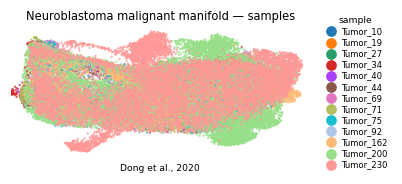

In [12]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=8, alpha=.8, frameon=False, show=False, ax=ax)
h,l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02,.5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title('Neuroblastoma malignant manifold — samples', size=7.5)
ax.text(.5,-.12,'Dong et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', adata.shape[0], '| samples:', adata.obs['sample'].nunique())